# Supply Chain Analysis: Operations & Logistics (DataCo)

Notebook ini menganalisis performa pengiriman dan operasi pesanan pada dataset DataCo Smart Supply Chain (2015 sampai Januari 2018).

## 1. Business Understanding

Analisis ini membantu menjawab: **seberapa andal pengiriman, di mana masalahnya, dan apa yang sebaiknya diperbaiki.**

1. Berapa persen pesanan terlambat, dan seberapa terlambat?
2. Shipping mode mana yang paling sering terlambat, dan apakah masalahnya ada di janji (jadwal) atau di realisasi?
3. Apakah wilayah, market, kategori, atau segmen pelanggan memengaruhi keterlambatan?
4. Berapa persen pesanan dibatalkan atau dicurigai fraud, dan terkonsentrasi di tipe pembayaran mana?
5. Apakah keterlambatan berdampak pada profit?
6. Departemen dan produk mana yang paling sering berprofit negatif?
7. Bagaimana tren pesanan dan keterlambatan dari waktu ke waktu?
8. Kalau jadwal pengiriman diubah, berapa keterlambatan turun? (simulasi)

**Level analisis:** metrik layanan (keterlambatan, pembatalan) dihitung **per order** (65.752 order), sedangkan metrik profit dihitung **per item pesanan** (180.519 baris).

## 2. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 3. Import Dataset

In [ ]:
FILE = "DataCoSupplyChainDataset.csv"
df_raw = pd.read_csv(FILE, encoding="latin-1")   # file ini memakai encoding latin-1
print("Bentuk data:", df_raw.shape)

Bentuk data: (180519, 53)


## 4. Data Understanding

In [ ]:
info = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "n_null": df_raw.isna().sum(),
})
print(info)

print("Baris (item pesanan):", len(df_raw),
      "| Order:", df_raw["Order Id"].nunique(),
      "| Pelanggan:", df_raw["Customer Id"].nunique())
print("Contoh format tanggal:", df_raw["order date (DateOrders)"].iloc[0], "|",
      df_raw["shipping date (DateOrders)"].iloc[0])
print(df_raw["Delivery Status"].value_counts())
print(df_raw["Order Status"].value_counts())

# Apakah status terlambat identik dengan Late_delivery_risk?
print(pd.crosstab(df_raw["Delivery Status"], df_raw["Late_delivery_risk"]))
print("Isi kolom data pribadi:", df_raw["Customer Email"].unique(), df_raw["Customer Password"].unique())

                                 dtype  n_unique  n_null
Type                            object         4       0
Days for shipping (real)         int64         7       0
Days for shipment (scheduled)    int64         4       0
Benefit per order              float64     21998       0
Sales per customer             float64      2927       0
Delivery Status                 object         4       0
Late_delivery_risk               int64         2       0
Category Id                      int64        51       0
Category Name                   object        50       0
Customer City                   object       563       0
Customer Country                object         2       0
Customer Email                  object         1       0
Customer Fname                  object       782       0
Customer Id                      int64     20652       0
Customer Lname                  object      1109       8
Customer Password               object         1       0
Customer Segment               

**Kesimpulan:** ___

## 5. Data Preprocessing

In [ ]:
RENAME = {
    "Order Id": "order_id", "Order Item Id": "order_item_id", "Customer Id": "customer_id",
    "order date (DateOrders)": "order_date", "shipping date (DateOrders)": "ship_date",
    "Shipping Mode": "shipping_mode", "Days for shipment (scheduled)": "days_scheduled",
    "Days for shipping (real)": "days_real", "Delivery Status": "delivery_status",
    "Late_delivery_risk": "late", "Order Status": "order_status", "Type": "payment_type",
    "Market": "market", "Order Region": "region", "Order Country": "country",
    "Customer Segment": "segment", "Department Name": "department",
    "Category Name": "category", "Product Name": "product",
    "Order Item Quantity": "quantity", "Order Item Discount Rate": "discount_rate",
    "Sales": "gross_sales", "Order Item Total": "net_sales", "Order Profit Per Order": "profit",
}

def preprocess(df_raw):
    df = df_raw[list(RENAME)].rename(columns=RENAME).copy()

    # --- Cleaning dan feature engineering ---
    df["order_date"] = pd.to_datetime(df["order_date"], format="%m/%d/%Y %H:%M")
    df["ship_date"] = pd.to_datetime(df["ship_date"], format="%m/%d/%Y %H:%M")
    df["year"] = df["order_date"].dt.year
    df["bulan"] = df["order_date"].dt.to_period("M").astype(str)
    df["gap"] = df["days_real"] - df["days_scheduled"]          # positif = lebih lambat dari janji
    df["batal"] = df["delivery_status"].eq("Shipping canceled")
    df["profit_negatif"] = df["profit"] < 0

    # --- Validasi otomatis (gagal keras jika data tidak sesuai harapan) ---
    assert len(df) == 180_519, f"Jumlah baris tidak sesuai: {len(df)}"
    assert df["order_item_id"].is_unique, "order_item_id tidak unik"
    assert df["order_id"].nunique() == 65_752, "Jumlah order tidak sesuai"
    assert df["customer_id"].nunique() == 20_652, "Jumlah pelanggan tidak sesuai"
    assert df.isna().sum().sum() == 0, "Ada nilai kosong"
    assert (df["ship_date"] >= df["order_date"]).all(), "Ada tanggal kirim sebelum tanggal order"
    assert ((df["late"] == 1) == (df["delivery_status"] == "Late delivery")).all(), "late tidak sama dengan status terlambat"
    layanan = ["shipping_mode", "days_scheduled", "days_real", "late", "market", "region", "segment", "order_status", "payment_type"]
    assert df.groupby("order_id")[layanan].nunique().max().max() == 1, "Atribut layanan tidak konsisten per order"
    assert abs(df["late"].mean() * 100 - 54.83) < 0.01, "Rasio terlambat tidak sesuai"
    assert abs(df["profit"].sum() - 3_966_903) < 1, "Total profit tidak sesuai"
    print("Validasi lolos:", df.shape)
    return df

df = preprocess(df_raw)

# Tabel level order (untuk metrik layanan)
ATRIBUT_ORDER = ["shipping_mode", "days_scheduled", "days_real", "gap", "delivery_status", "late", "batal",
                 "order_status", "payment_type", "market", "region", "country", "segment",
                 "order_date", "year", "bulan", "customer_id"]
orders = df.groupby("order_id").agg(
    **{c: (c, "first") for c in ATRIBUT_ORDER},
    items=("order_item_id", "count"),
    net_sales=("net_sales", "sum"),
    profit=("profit", "sum"),
).reset_index()
print("Tabel order:", orders.shape)

Validasi lolos: (180519, 29)
Tabel order: (65752, 21)


**Kesimpulan:** ___

## 6. Exploratory Data Analysis (EDA)

### 6.1 Seberapa banyak pesanan terlambat?

In [ ]:
n_order = len(orders)
status = orders["delivery_status"].value_counts().rename("order").to_frame()
status["porsi_%"] = status["order"] / n_order * 100
print(status.round(2))

print("Order terlambat (semua order):", round(orders["late"].mean() * 100, 2), "%")
print("Order terlambat (tanpa order batal):", round(orders.loc[~orders["batal"], "late"].mean() * 100, 2), "%")

telat = orders[orders["late"] == 1]
print("Rata-rata keterlambatan pada order terlambat (hari):", round(telat["gap"].mean(), 2))
print(telat["gap"].value_counts().sort_index())

                   order  porsi_%
delivery_status                  
Late delivery      36048    54.82
Advance shipping   15127    23.01
Shipping on time   11722    17.83
Shipping canceled   2855     4.34
Order terlambat (semua order): 54.82 %
Order terlambat (tanpa order batal): 57.31 %
Rata-rata keterlambatan pada order terlambat (hari): 1.62
gap
1    21130
2    10010
3     2452
4     2456
Name: count, dtype: int64


**Kesimpulan 6.1:** ___

### 6.2 Performa per shipping mode

                order  janji_hari  aktual_hari  terlambat_pct  terlambat_tanpa_batal_pct
shipping_mode                                                                           
First Class     10079         1.0         2.00          95.27                     100.00
Second Class    12778         2.0         4.00          76.72                      79.99
Same Day         3571         0.0         0.48          46.15                      48.37
Standard Class  39324         4.0         4.00          38.13                      39.85


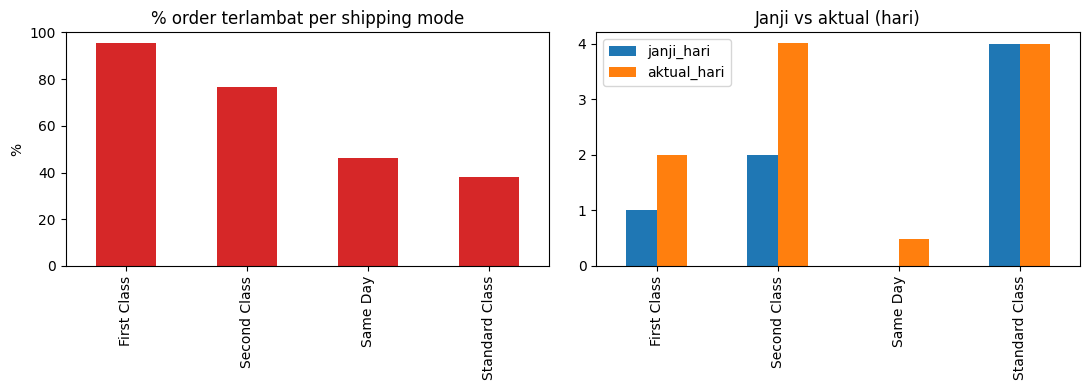

In [ ]:
by_mode = orders.groupby("shipping_mode").agg(
    order=("late", "size"),
    janji_hari=("days_scheduled", "mean"),
    aktual_hari=("days_real", "mean"),
    terlambat_pct=("late", lambda s: s.mean() * 100),
)
tanpa_batal = orders[~orders["batal"]].groupby("shipping_mode")["late"].mean() * 100
by_mode["terlambat_tanpa_batal_pct"] = tanpa_batal
by_mode = by_mode.sort_values("terlambat_pct", ascending=False)
print(by_mode.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
by_mode["terlambat_pct"].plot(kind="bar", ax=ax[0], color="tab:red", title="% order terlambat per shipping mode")
ax[0].set_ylabel("%"); ax[0].set_xlabel("")
by_mode[["janji_hari", "aktual_hari"]].plot(kind="bar", ax=ax[1], title="Janji vs aktual (hari)")
ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("shipping_mode.png", dpi=150); plt.show()

**Kesimpulan 6.2:** ___

### 6.3 Apakah wilayah, segmen, dan departemen memengaruhi keterlambatan?

              order  terlambat_pct
market                            
Africa         3854          54.13
LATAM         17181          54.36
USCA           8579          54.83
Europe        18561          54.95
Pacific Asia  17577          55.30
             order  terlambat_pct
segment                          
Consumer     34119          54.73
Corporate    19856          54.75
Home Office  11777          55.23
                 order  terlambat_pct
region                               
Canada             309          49.51
West Africa       1223          51.19
Caribbean         2806          52.99
Southern Europe   3543          53.49
Northern Europe   3716          53.71
Southern Africa    398          53.77
South America     4979          54.15
North Africa      1064          54.32
West of USA       2667          54.41
Oceania           4362          54.61
Eastern Asia      3318          54.79
Central America   9396          54.87
East of USA       2323          54.93
US Center      

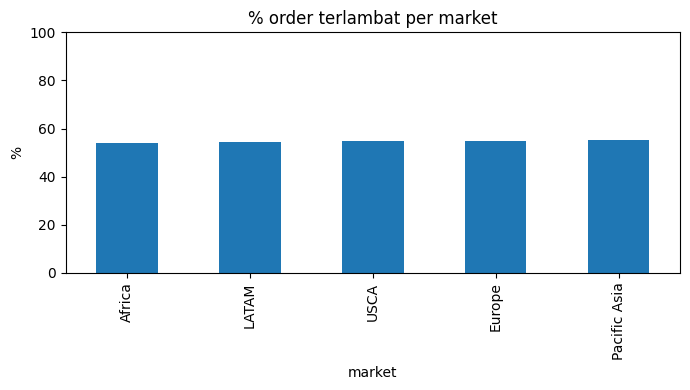

In [ ]:
def late_by(col, data=orders):
    t = data.groupby(col).agg(order=("late", "size"), terlambat_pct=("late", lambda s: s.mean() * 100))
    return t.sort_values("terlambat_pct").round(2)

print(late_by("market"))
print(late_by("segment"))
print(late_by("region"))
print(late_by("year"))
print(late_by("department", df).rename(columns={"order": "item"}))   # level item

m = late_by("market")
ax = m["terlambat_pct"].plot(kind="bar", figsize=(7, 4), title="% order terlambat per market")
ax.set_ylim(0, 100); ax.set_ylabel("%")
plt.tight_layout(); plt.savefig("late_per_market.png", dpi=150); plt.show()

**Kesimpulan 6.3:** ___

### 6.4 Pembatalan dan dugaan fraud

In [ ]:
print(pd.crosstab(orders["order_status"], orders["payment_type"]))

n_batal = (orders["order_status"] == "CANCELED").sum()
n_fraud = (orders["order_status"] == "SUSPECTED_FRAUD").sum()
print("Order CANCELED:", n_batal, f"({n_batal / n_order * 100:.2f}%)",
      "| SUSPECTED_FRAUD:", n_fraud, f"({n_fraud / n_order * 100:.2f}%)")
print("Order dengan status pengiriman 'Shipping canceled':", int(orders["batal"].sum()))

payment_type     CASH  DEBIT  PAYMENT  TRANSFER
order_status                                   
CANCELED            0      0        0      1367
CLOSED           7249      0        0         0
COMPLETE            0  21716        0         0
ON_HOLD             0   3624        0         0
PAYMENT_REVIEW      0      0      704         0
PENDING             0      0        0      7321
PENDING_PAYMENT     0      0    14382         0
PROCESSING          0      0        0      7901
SUSPECTED_FRAUD     0      0        0      1488
Order CANCELED: 1367 (2.08%) | SUSPECTED_FRAUD: 1488 (2.26%)
Order dengan status pengiriman 'Shipping canceled': 2855


**Kesimpulan 6.4:** ___

### 6.5 Tren bulanan

         order  terlambat_pct
bulan                        
2015-01   1787          53.89
2015-02   1585          54.95
2015-03   1781          54.91
2015-04   1710          54.21
2015-05   1776          54.56
2015-06   1725          54.55
         order  terlambat_pct
bulan                        
2017-11   2055          55.09
2017-12   2124          55.18
2018-01   2123          56.29


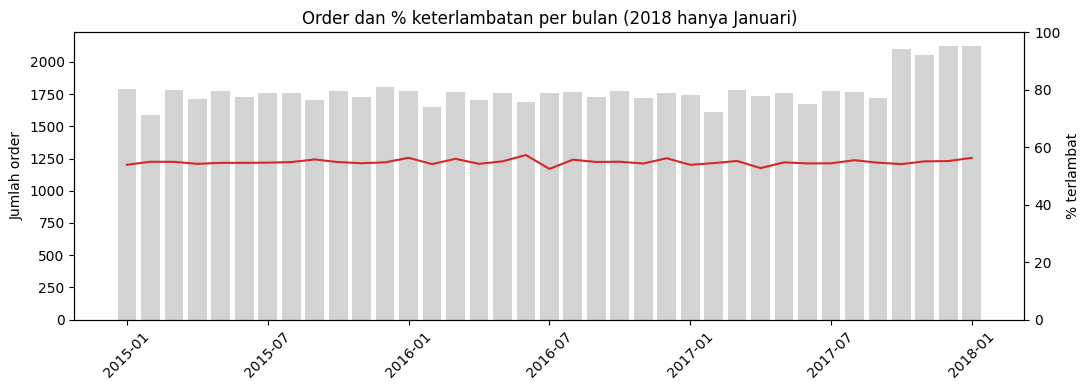

In [ ]:
tren = orders.groupby("bulan").agg(order=("late", "size"), terlambat_pct=("late", lambda s: s.mean() * 100))
print(tren.round(2).head(6))
print(tren.round(2).tail(3))

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(tren.index, tren["order"], color="lightgray")
ax1.set_ylabel("Jumlah order")
ax1.set_xticks(range(0, len(tren), 6)); ax1.set_xticklabels(tren.index[::6], rotation=45)
ax2 = ax1.twinx()
ax2.plot(tren.index, tren["terlambat_pct"], color="tab:red")
ax2.set_ylim(0, 100); ax2.set_ylabel("% terlambat")
plt.title("Order dan % keterlambatan per bulan (2018 hanya Januari)")
plt.tight_layout(); plt.savefig("tren_bulanan.png", dpi=150); plt.show()

**Kesimpulan 6.5:** ___

### 6.6 Profit (level item pesanan)

In [ ]:
total_profit = df["profit"].sum()
total_net = df["net_sales"].sum()
print("Total profit:", round(total_profit), "| Net sales:", round(total_net),
      "| Margin:", round(total_profit / total_net * 100, 2), "%")
print("Baris profit negatif:", int(df["profit_negatif"].sum()), f"({df['profit_negatif'].mean() * 100:.1f}%)")

print(df.groupby("delivery_status")["profit"].agg(["count", "mean", "sum"]).round(1))

neg_dep = df.groupby("department").agg(
    item=("profit", "size"),
    profit_negatif_pct=("profit_negatif", lambda s: s.mean() * 100),
    profit=("profit", "sum"),
).sort_values("profit_negatif_pct", ascending=False)
print(neg_dep.round(1))

Total profit: 3966903 | Net sales: 33054402 | Margin: 12.0 %
Baris profit negatif: 33784 (18.7%)
                   count  mean        sum
delivery_status                          
Advance shipping   41592  22.5   935225.3
Late delivery      98977  21.6  2140051.7
Shipping canceled   7754  20.7   160482.3
Shipping on time   32196  22.7   731143.7
                     item  profit_negatif_pct     profit
department                                              
Health and Beauty     362                23.5     9493.6
Pet Shop              492                21.1     3589.3
Discs Shop           2026                19.7    24193.1
Book Shop             405                19.3      883.0
Golf                33220                19.0   497523.6
Apparel             48998                18.7   881882.9
Fan Shop            66861                18.7  1834155.4
Footwear            14525                18.6   410222.5
Outdoors             9686                17.9   145251.5
Technology           146

**Kesimpulan 6.6:** ___

## 7. Analisis Lanjutan

### 7.1 Estimasi vs realisasi
Apakah keterlambatan disebabkan oleh estimasi waktu, atau oleh proses pengiriman yang lambat?

In [ ]:
dist = pd.crosstab(orders["shipping_mode"], orders["days_real"], normalize="index") * 100
print(dist.round(1))
print(orders.groupby("shipping_mode")[["days_scheduled", "days_real", "gap"]].mean().round(2))

days_real          0     1      2     3     4     5     6
shipping_mode                                            
First Class      0.0   0.0  100.0   0.0   0.0   0.0   0.0
Same Day        51.6  48.4    0.0   0.0   0.0   0.0   0.0
Second Class     0.0   0.0   20.1  19.8  20.1  20.0  20.1
Standard Class   0.0   0.0   20.1  20.0  20.0  19.8  20.1
                days_scheduled  days_real   gap
shipping_mode                                  
First Class                1.0       2.00  1.00
Same Day                   0.0       0.48  0.48
Second Class               2.0       4.00  2.00
Standard Class             4.0       4.00 -0.00


**Kesimpulan 7.1:** ___

### 7.2 Apakah perbedaan antar kelompok nyata? (rentang kepercayaan 95%)

In [ ]:
def prop_ci(s):
    n, p = len(s), s.mean()
    se = np.sqrt(p * (1 - p) / n)
    return pd.Series({"order": n, "terlambat_%": p * 100,
                      "batas_bawah": (p - 1.96 * se) * 100, "batas_atas": (p + 1.96 * se) * 100})

for kolom in ["shipping_mode", "market", "segment"]:
    print(orders.groupby(kolom)["late"].apply(prop_ci).unstack().round(2))

                  order  terlambat_%  batas_bawah  batas_atas
shipping_mode                                                
First Class     10079.0        95.27        94.85       95.68
Same Day         3571.0        46.15        44.51       47.78
Second Class    12778.0        76.72        75.98       77.45
Standard Class  39324.0        38.13        37.65       38.61
                order  terlambat_%  batas_bawah  batas_atas
market                                                     
Africa         3854.0        54.13        52.55       55.70
Europe        18561.0        54.95        54.23       55.66
LATAM         17181.0        54.36        53.61       55.10
Pacific Asia  17577.0        55.30        54.56       56.03
USCA           8579.0        54.83        53.78       55.88
               order  terlambat_%  batas_bawah  batas_atas
segment                                                   
Consumer     34119.0        54.73        54.20       55.25
Corporate    19856.0        54.

**Kesimpulan 7.2:** ___

### 7.3 Apakah keterlambatan berdampak pada profit? (level item)

In [ ]:
a = df.loc[df["late"] == 1, "profit"]
b = df.loc[(df["late"] == 0) & (~df["batal"]), "profit"]
diff = a.mean() - b.mean()
se = np.sqrt(a.var() / len(a) + b.var() / len(b))
print("Rata-rata profit per item, terlambat:", round(a.mean(), 2), "| tepat waktu atau lebih awal:", round(b.mean(), 2))
print("Selisih:", round(diff, 2), "| rentang 95%:", round(diff - 1.96 * se, 2), "sampai", round(diff + 1.96 * se, 2))

Rata-rata profit per item, terlambat: 21.62 | tepat waktu atau lebih awal: 22.58
Selisih: -0.96 | rentang 95%: -1.95 sampai 0.03


**Kesimpulan 7.3:** ___ *(Catatan: item dalam satu order saling berkaitan, jadi rentangnya kemungkinan sedikit terlalu sempit.)*

### 7.4 Simulasi: jika jadwal pengiriman diubah
Keterlambatan dihitung ulang dari hari aktual yang ada (`days_real`) terhadap jadwal baru, **tanpa order batal**. Perhatikan bahwa mengubah jadwal hanya mengubah **janji**, bukan kecepatan pengiriman.

In [ ]:
nb = orders[~orders["batal"]]
baris = []
for mode, sub in nb.groupby("shipping_mode"):
    for jadwal in range(int(sub["days_scheduled"].iloc[0]), 7):
        baris.append((mode, jadwal, (sub["days_real"] > jadwal).mean() * 100))
sim = pd.DataFrame(baris, columns=["shipping_mode", "jadwal_baru_hari", "terlambat_pct"]).round(1)
print(sim.pivot(index="jadwal_baru_hari", columns="shipping_mode", values="terlambat_pct"))

shipping_mode     First Class  Same Day  Second Class  Standard Class
jadwal_baru_hari                                                     
0                         NaN      48.4           NaN             NaN
1                       100.0       0.0           NaN             NaN
2                         0.0       0.0          80.0             NaN
3                         0.0       0.0          60.2             NaN
4                         0.0       0.0          40.0            39.8
5                         0.0       0.0          20.0            20.0
6                         0.0       0.0           0.0             0.0


**Kesimpulan 7.4:** ___

### 7.5 Apakah ada sinyal lain di luar shipping mode? (pembanding prediksi)
Akurasi tebakan berbasis tabel mayoritas (data latih 80%, uji 20% per order). **Fitur yang dilarang** karena membocorkan jawaban: `delivery_status`, `days_real`, `ship_date`, `gap`. Hanya fitur yang diketahui saat pesanan dibuat yang dipakai.

In [ ]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(orders))
cut = int(len(orders) * 0.8)
train, test = orders.iloc[idx[:cut]], orders.iloc[idx[cut:]]
mayoritas_global = int(train["late"].mean() >= 0.5)

def akurasi(fitur):
    if not fitur:
        pred = np.full(len(test), mayoritas_global)
    else:
        tabel = (train.groupby(fitur)["late"].mean() >= 0.5).astype(int).rename("pred")
        pred = test.join(tabel, on=fitur)["pred"].fillna(mayoritas_global).astype(int).to_numpy()
    return (pred == test["late"].to_numpy()).mean() * 100

kandidat = [
    [],
    ["shipping_mode"],
    ["shipping_mode", "market"],
    ["shipping_mode", "region"],
    ["shipping_mode", "segment"],
    ["shipping_mode", "payment_type"],
    ["shipping_mode", "market", "segment", "payment_type"],
]
hasil = pd.DataFrame({
    "fitur": ["(tanpa fitur: selalu tebak mayoritas)" if not f else " + ".join(f) for f in kandidat],
    "akurasi_%": [akurasi(f) for f in kandidat],
}).round(1)
print(hasil)

                                             fitur  akurasi_%
0            (tanpa fitur: selalu tebak mayoritas)       54.9
1                                    shipping_mode       69.7
2                           shipping_mode + market       69.7
3                           shipping_mode + region       69.6
4                          shipping_mode + segment       69.7
5                     shipping_mode + payment_type       69.7
6  shipping_mode + market + segment + payment_type       69.6


**Kesimpulan 7.5:** ___

## 8. Insight & Rekomendasi

### 8.1 Tabel ringkasan keputusan per shipping mode

In [ ]:
ringkasan_mode = by_mode.copy()
ringkasan_mode["selisih_janji_aktual_hari"] = ringkasan_mode["aktual_hari"] - ringkasan_mode["janji_hari"]
print(ringkasan_mode[["order", "janji_hari", "aktual_hari", "selisih_janji_aktual_hari",
                      "terlambat_pct", "terlambat_tanpa_batal_pct"]].round(2))

                order  janji_hari  aktual_hari  selisih_janji_aktual_hari  terlambat_pct  terlambat_tanpa_batal_pct
shipping_mode                                                                                                      
First Class     10079         1.0         2.00                       1.00          95.27                     100.00
Second Class    12778         2.0         4.00                       2.00          76.72                      79.99
Same Day         3571         0.0         0.48                       0.48          46.15                      48.37
Standard Class  39324         4.0         4.00                      -0.00          38.13                      39.85


**Rekomendasi:**
1. ___
2. ___
3. ___
4. ___
5. ___

## 9. Ekspor

In [ ]:
orders.to_excel("supply_chain_order.xlsx", index=False)
df.to_excel("supply_chain_item.xlsx", index=False)
ringkasan_mode.reset_index().to_csv("shipping_mode_summary.csv", index=False)
print("Tersimpan: supply_chain_item.csv, supply_chain_order.csv, shipping_mode_summary.csv")

Tersimpan: supply_chain_item.csv, supply_chain_order.csv, shipping_mode_summary.csv


In [ ]:
# item_cek = pd.read_csv("supply_chain_item.csv")
# order_cek = pd.read_csv("supply_chain_order.csv")
# print("supply_chain_item.csv:", item_cek.shape, "| supply_chain_order.csv:", order_cek.shape)
# print("Cocok dengan data asli:", len(item_cek) == 180_519 and len(order_cek) == 65_752
#       and abs(item_cek["profit"].sum() - 3_966_903) < 1)
orders.to_excel("supply_chain_order.xlsx", index=False)
df.to_excel("supply_chain_item.xlsx", index=False)
print("Tersimpan: 3 file CSV dan 2 file XLSX")

Tersimpan: 3 file CSV dan 2 file XLSX


**Keterbatasan:**
- Dataset tampak **sintetis/simulasi** (hari aktual tersebar merata, status order ditentukan tipe pembayaran, keterlambatan tidak bervariasi menurut wilayah atau waktu). Temuan menunjukkan metode analisis, bukan kondisi operasi perusahaan nyata.
- Data 2018 hanya Januari, sehingga tidak dibandingkan dengan tahun penuh.
- Tidak ada data level stok, jadi analisis inventory tidak dilakukan.
- Simulasi jadwal hanya mengubah janji, bukan kecepatan pengiriman.
- Rentang kepercayaan memperlakukan order sebagai pengamatan bebas.